# [Lab Session 3](fourier.ipynb)


In [1]:
import numpy as np
import matplotlib.pyplot as plt

from skimage.transform import resize

**[Task 1 (a).]()** Load the first image, resize it to (256, 256) and display it.


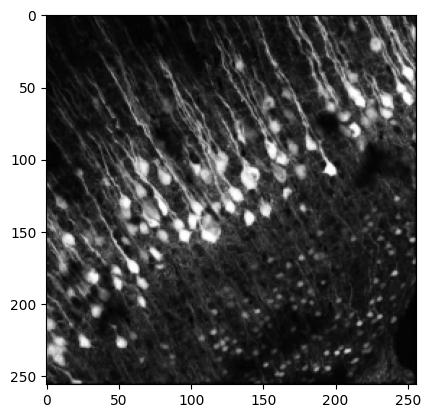

In [3]:
cell_img = plt.imread('data/cells.png')
cell_img = resize(cell_img, (256, 256))

plt.figure()
plt.imshow(cell_img, cmap='gray')
plt.show()

**[Task 1 (b).]()** Apply the fast Fourier transform and check the data type of the result.


In [5]:
cell_ft = np.fft.fft2(cell_img)

print(cell_ft.dtype)

complex128


**[Task 1 (c).]()** Extract the phase and amplitude and display them.


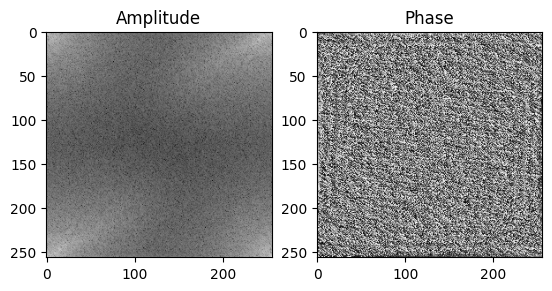

In [7]:
amplitude = np.abs(cell_ft)
phase = np.angle(cell_ft)

plt.figure()

plt.subplot(1, 2, 1)
plt.imshow(np.log(amplitude), cmap='gray')
plt.title('Amplitude')

plt.subplot(1, 2, 2)
plt.imshow(phase, cmap='gray')
plt.title('Phase')

plt.show()

**[Task 1 (d).]()** Do a shift so that zero is displayed in the center of the image and show amplitude and phase again.


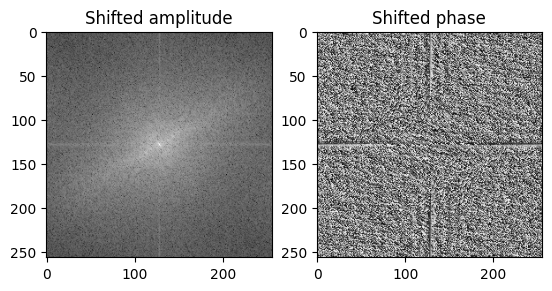

In [8]:
cell_ft_shifted = np.fft.fftshift(cell_ft)

amplitude_shifted = np.abs(cell_ft_shifted)
phase_shifted = np.angle(cell_ft_shifted)

plt.figure()

plt.subplot(1, 2, 1)
plt.imshow(np.log(amplitude_shifted), cmap='gray')
plt.title('Shifted amplitude')

plt.subplot(1, 2, 2)
plt.imshow(phase_shifted, cmap='gray')
plt.title('Shifted phase')

plt.show()

**[Task 1 (e).]()** Apply the inverse FFT and display the restored image.


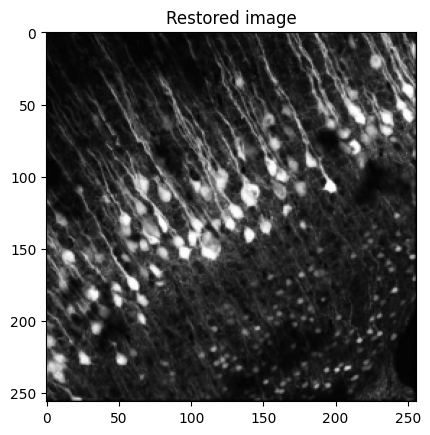

In [9]:
cell_ft_unshifted = np.fft.ifftshift(cell_ft_shifted)

cell_restored = np.fft.ifft2(cell_ft_unshifted)

cell_restored = cell_restored.real

plt.figure()
plt.imshow(cell_restored, cmap='gray')
plt.title('Restored image')
plt.show()

---


**[Task 2 (a).]()** Load the brain MR image.


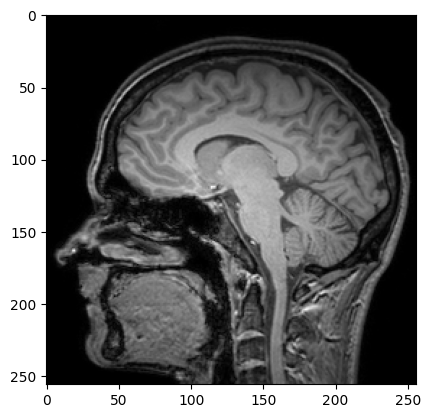

In [10]:
brain_img = plt.imread('data/brain_mri.png')
brain_img = resize(brain_img, (256, 256))

plt.figure()
plt.imshow(brain_img, cmap='gray')
plt.show()

**[Task 2 (b).]()** Apply the FFT, do a shift, extract amplitude and phase.


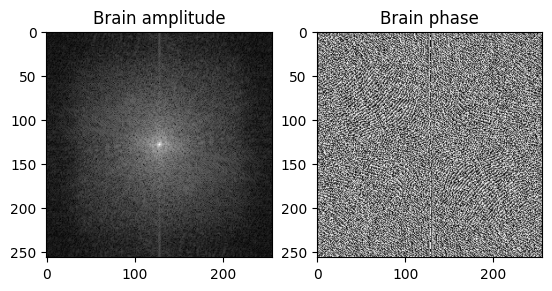

In [11]:
brain_ft = np.fft.fft2(brain_img)
brain_ft_shifted = np.fft.fftshift(brain_ft)

brain_amplitude = np.abs(brain_ft_shifted)
brain_phase = np.angle(brain_ft_shifted)

plt.figure()

plt.subplot(1, 2, 1)
plt.imshow(np.log(brain_amplitude + 1), cmap='gray')
plt.title('Brain amplitude')

plt.subplot(1, 2, 2)
plt.imshow(brain_phase, cmap='gray')
plt.title('Brain phase')

plt.show()

In [12]:
def to_complex_array(amplitude_array, phase_array):
    return amplitude_array * np.exp(1j * phase_array)

**[Task 2 (c).]()** Merge the amplitude of the brain MR image and the phase of cell image. Do the IFFT and display the resulting image.


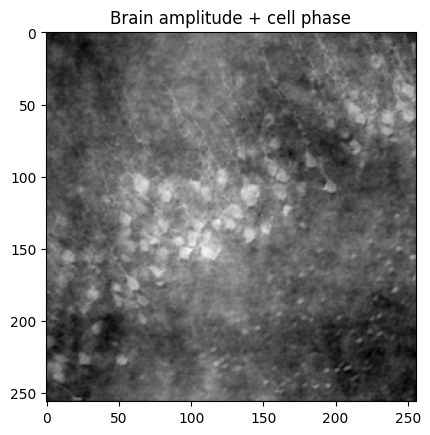

In [13]:
cell_ft_shifted = np.fft.fftshift(cell_ft)

cell_amplitude = np.abs(cell_ft_shifted)
cell_phase = np.angle(cell_ft_shifted)


merged_ft = to_complex_array(brain_amplitude, cell_phase)

merged_ft = np.fft.ifftshift(merged_ft)
merged_img = np.fft.ifft2(merged_ft).real

plt.figure()
plt.imshow(merged_img, cmap='gray')
plt.title('Brain amplitude + cell phase')
plt.show()

**[Task 2 (d).]()** Repeat this with the amplitude of the cells and the phase of the brain.


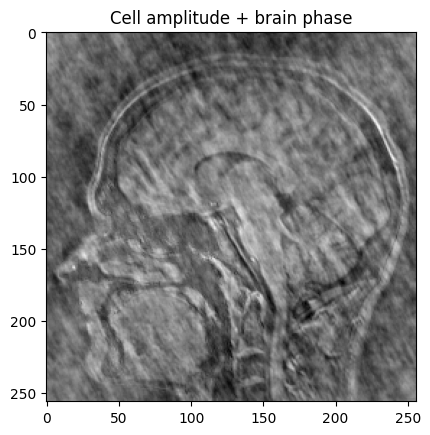

In [14]:
merged_ft = to_complex_array(cell_amplitude, brain_phase)

merged_ft = np.fft.ifftshift(merged_ft)
merged_img = np.fft.ifft2(merged_ft).real

plt.figure()
plt.imshow(merged_img, cmap='gray')
plt.title('Cell amplitude + brain phase')
plt.show()

The phase carries more information about the image than the amplitude. 

-> When combining the brain amplitude with the cell phase, the resulting image looks more like the cell image. 

-> When combining the cell amplitude with the brain phase, it looks more like the brain image. 

  => This shows that the phase is more important for preserving the overall structure and recognizable features of an image. 

---


**[Task 3 (a).]()** Create a lowpass filter mask.


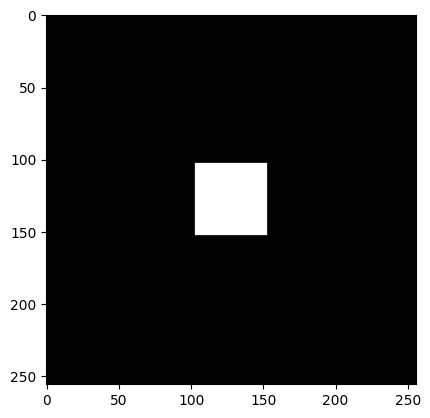

In [15]:
filter_window_size = 50

mask_low = np.zeros(brain_img.shape)

center_y = brain_img.shape[0] // 2
center_x = brain_img.shape[1] // 2

mask_low[
    center_y - filter_window_size//2 : center_y + filter_window_size//2,
    center_x - filter_window_size//2 : center_x + filter_window_size//2
] = 1

plt.imshow(mask_low, cmap='gray')
plt.show()

**[Task 3 (b).]()** Create a highpass filter maks.


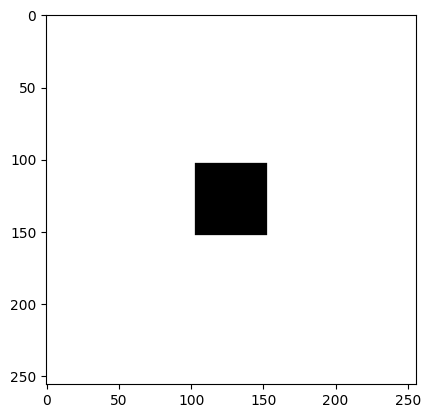

In [17]:
mask_high = 1 - mask_low

plt.figure()
plt.imshow(mask_high, cmap='gray')
plt.show()

**[Task 3 (c).]()** Apply the lowpass and highpass filter mask to the amplitude of the brain and display the results.


In [18]:
amplitude_low = brain_amplitude * mask_low
amplitude_high = brain_amplitude * mask_high

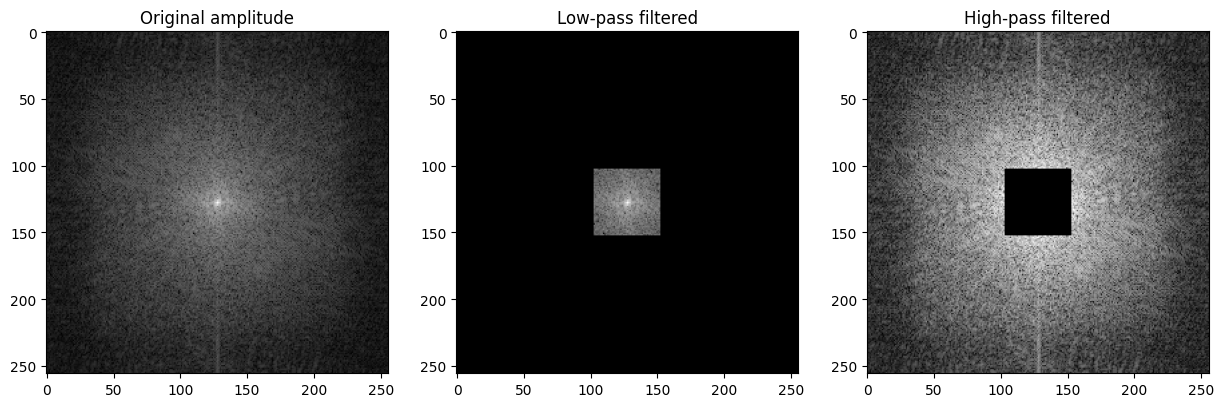

In [ ]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(np.log(brain_amplitude + 1), cmap='gray')
plt.title('Original amplitude')

plt.subplot(1, 3, 2)
plt.imshow(np.log(amplitude_low + 1), cmap='gray')
plt.title('Low-pass filtered')

plt.subplot(1, 3, 3)
plt.imshow(np.log(amplitude_high + 1), cmap='gray')
plt.title('High-pass filtered')

plt.show()

**[Task 3 (d).]()** Apply the mask to the amplitude, merge the result with the phase and restore the image.


Low-pass filtered image:

In [22]:

low_ft = to_complex_array(amplitude_low, brain_phase)
low_ft = np.fft.ifftshift(low_ft)
low_img = np.fft.ifft2(low_ft).real

High-pass filtered image:

In [23]:
high_ft = to_complex_array(amplitude_high, brain_phase)
high_ft = np.fft.ifftshift(high_ft)
high_img = np.fft.ifft2(high_ft).real

DIsplaying the images:

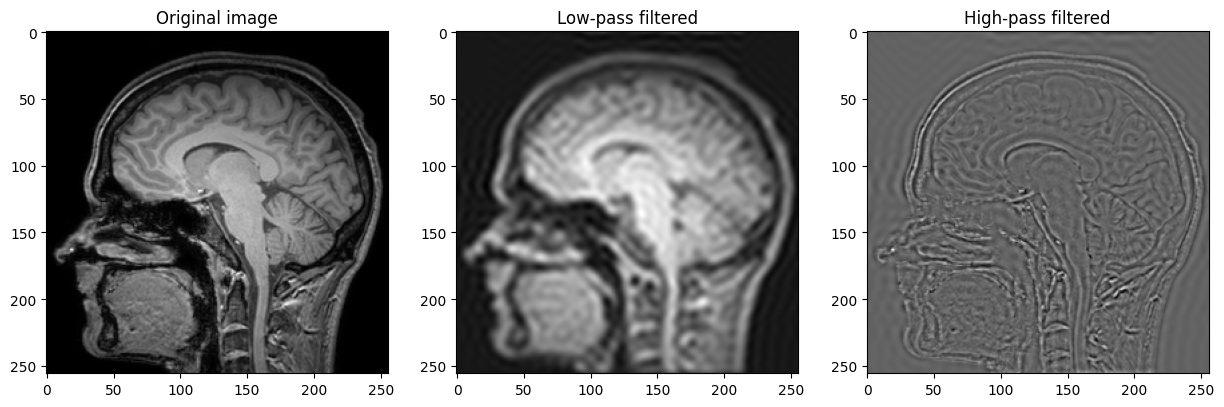

In [24]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(brain_img, cmap='gray')
plt.title('Original image')

plt.subplot(1, 3, 2)
plt.imshow(low_img, cmap='gray')
plt.title('Low-pass filtered')

plt.subplot(1, 3, 3)
plt.imshow(high_img, cmap='gray')
plt.title('High-pass filtered')

plt.show()

° Low-pass: The image becomes blurry because high frequencies (fine details and edges) are removed.

° High-pass: The image loses its gradual intensity changes, while edges and fine details become more visible.

When increasing the filter size, more frequencies are retained in the low-pass filtered image, so more details become visible and the image becomes less blurry. 

In contrast, the high-pass filter removes more low frequencies as the filter size increases, leaving mainly the higher frequencies and fine details.

---


**[Task 4 (a).]()** Implement a function that computes the 2D-DFT.


In [25]:
def my_dft(img):
    M, N = img.shape
    dft = np.zeros(img.shape, dtype=complex)

    for u in range(M):
        for v in range(N):
            for x in range(M):
                for y in range(N):
                    dft[u, v] += img[x, y] * np.exp(
                        -2j * np.pi * (u*x/M + v*y/N)
                    )

    dft = dft / (M*N)

    return dft

**[Task 4 (b).]()** Implement a function that computes the 2D-IDFT.


In [26]:
def my_idft(dft):
    M, N = dft.shape
    idft = np.zeros(dft.shape, dtype=complex)

    for u in range(M):
        for v in range(N):
            for x in range(M):
                for y in range(N):
                    idft[u, v] += dft[x, y] * np.exp(
                        2j * np.pi * (u*x/M + v*y/N)
                    )

    return idft

Due to high computational costs, we need to resize the image.


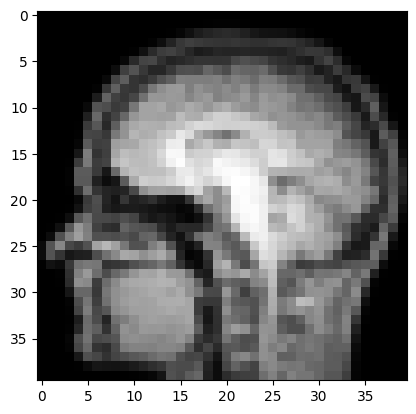

In [27]:
test_img = resize(brain_img, (40, 40))
plt.imshow(test_img, 'gray')

**[Task 4 (c).]()** Apply your DFT implementation to the image and display amplitude and phase.


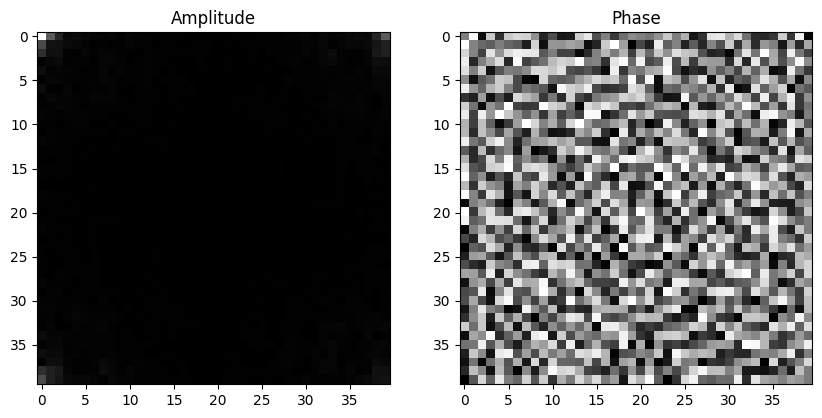

In [29]:
own_dft = my_dft(test_img)

amplitude = np.abs(own_dft)
phase = np.angle(own_dft)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(np.log(amplitude + 1), cmap='gray')
plt.title('Amplitude')

plt.subplot(1, 2, 2)
plt.imshow(phase, cmap='gray')
plt.title('Phase')

plt.show()

**[Task 4 (d).]()** Reconstruct the image using your IDFT implementation and display it.


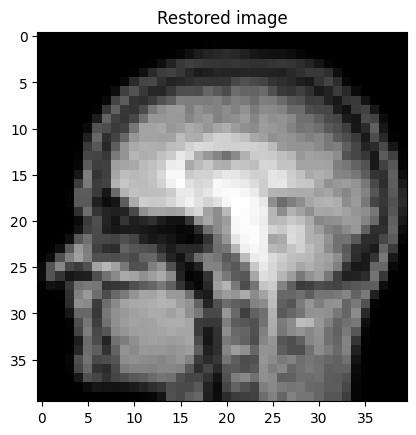

In [31]:
restored_img = my_idft(own_dft).real

plt.figure()
plt.imshow(restored_img, cmap='gray')
plt.title('Restored image')
plt.show()

This result is expected because we resized the picture, which led to losing some details.

**[Task 4 (e).]()** Compare your result to the result of numpy's FFT


In [33]:
np_fft = np.fft.fft2(test_img, norm='forward')

print(np.allclose(own_dft, np_fft))

True


**[Task 4 (f).]()** Round the arrays and compare them again.


In [46]:
mean_difference = np.mean(np.abs(own_dft - np_fft))
print(mean_difference)

own_dft_rounded = np.round(own_dft, 12)
np_fft_rounded = np.round(np_fft, 12)

print((own_dft_rounded == np_fft_rounded).all())

7.541097048883874e-17
True


The highest number of decimal places at which the arrays still match exactly after rounding is 12!

**[Task 4 (g).]()** Compare the run times of the two algorithms (your DFT and numpy's FFT)


In [48]:
%timeit my_dft(test_img)

%timeit np.fft.fft2(test_img, norm='forward')

5.28 s ± 83.2 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)
38.5 μs ± 12 μs per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


My DFT: 5.28 s ± 83.2 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)

NumPy's FFT: 38.5 μs ± 12 μs per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


NumPy's FFT is much faster, because my DFT uses four nested loops to calculate every frequency individually, whereas NumPy's FFT uses a more efficient algorithm.